<a href="https://colab.research.google.com/github/AbrahamKonchellah/SemProject_MLEngine/blob/main/LogisticRegression_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Group Members:**

Somoine Abraham Konchellah - 189823

Onyango Keenan Joshua -   182887

Mechii Bonventure Mulama - 191614

**Problem Statement:**

Increasing Time Efficiency in Small legal practises by reducing time spent on non-billable activities like repeated document retrieval, retrieval of details e.g statements and deadlines from case documents and routine drafting.

Dataset source : https://huggingface.co/datasets/coastalcph/lex_glue

How this model supports the problem: LEDGAR contains contract provisions, each labelled with the type of clause it is (e.g. Governing Laws, Terminations, Notices). A classifier that tags clauses automatically can help a law firm:

i)Index and retrieve clauses by type instead of searching manually

ii)Find the relevant clause quickly when reviewing or comparing contracts

ii)Suggest the right clause category when drafting.

The ML approach is supervised, single-label, multi-class text classification. It is supervised because the examples already have labels. It is multi-class because there are 100 possible clause types. Each clause is assigned one type.

**2. Data Exploration**

The dataset is already split into *train* , *validation* and *test*


In [ ]:
# Import required libraries
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer , CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Set up charts and table display
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)

# Set random seed for consistent results
SEED = 42
np.random.seed(SEED)

# Model Settings
MAX_FEATURES = 30_000      # maximum number of text features to use
CV_FOLDS     = 3           # number of cross-validation folds
LR_C_GRID    = [1, 10, 100]  # controls how strongly Logistic Regression is regularised

In [ ]:
#Load the datasets directly from huggingface

!pip install -q datasets
from datasets import load_dataset

ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
label_names = ledgar["train"].features["label"].names
classes = len(label_names)

df_train = ledgar["train"].to_pandas()
df_validation = ledgar["validation"].to_pandas()
df_test = ledgar["test"].to_pandas()

README.md:   0%|          | 0.00/34.1k [00:00<?, ?B/s]

ledgar/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.9MB            

ledgar/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ledgar/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.31MB            

ledgar/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ledgar/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.44MB            

ledgar/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [ ]:
df_train.head()

,text,label
0,Except as otherwise set forth in this Debentur...,97
1,No ERISA Event has occurred or is reasonably e...,39
2,This Amendment may be executed by one or more ...,26
3,"From time to time, as and when required by the...",45
4,"Commencing March 7, 2016 and during the Employ...",11


In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    60000 non-null  object
 1   label   60000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 937.6+ KB


In [ ]:
print("Number of rows in train:", df_train.shape[0])
print("Number of columns in train:", df_train.shape[1])
print("Number of rows in validation:", df_validation.shape[0])
print("Number of columns validation:", df_validation.shape[1])
print("Number of rows in test:", df_test.shape[0])
print("Number of columns in test:", df_test.shape[1])

Number of rows in train: 60000
Number of columns in train: 2
Number of rows in validation: 10000
Number of columns validation: 2
Number of rows in test: 10000
Number of columns in test: 2


In [ ]:
print(f"Datatypes in the dataset:")
print(df_train.dtypes)

Datatypes in the dataset:
text     object
label     int64
dtype: object


In [ ]:
if df_train.isnull().sum().sum() ==0:
  print("The dataset is complete, no missing values")
else:
  print("The dataset is not complete, it has some missing values")

The dataset is complete, no missing values


In [ ]:
print("Missing values in each column:")
print(df_train.isnull().sum())

Missing values in each column:
text     0
label    0
dtype: int64


In [ ]:
df_train.describe()

,label
count,60000.000000
mean,50.874333
std,27.879258
min,0.000000
25%,26.000000
50%,48.000000
75%,76.000000
max,99.000000


In [ ]:

df_validation=ledgar["validation"].to_pandas()

df_validation.head()

,text,label
0,This Agreement may be amended from time to tim...,2
1,This Agreement embodies the entire agreement b...,2
2,The substantive laws of the State of Texas wil...,47
3,Section headings in this Amendment are include...,48
4,This Amendment shall be interpreted and constr...,47


In [ ]:
df_validation.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10000 non-null  object
 1   label   10000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 156.4+ KB


In [ ]:
print("Number of rows:", df_validation.shape[0])
print("Number of columns:", df_validation.shape[1])

Number of rows: 10000
Number of columns: 2


In [ ]:
if df_validation.isnull().sum().sum() ==0:
  print("The dataset is complete, no missing values")
else:
  print("The dataset is not complete, it is missing some values")

The dataset is complete, no missing values


In [ ]:
print("Missing values in each column:")
print(df_validation.isnull().sum())

Missing values in each column:
text     0
label    0
dtype: int64


In [ ]:
df_validation.describe()

,label
count,10000.000000
mean,51.404500
std,27.990738
min,0.000000
25%,28.000000
50%,49.000000
75%,77.000000
max,99.000000


In [ ]:
df_test.head()

,text,label
0,Executive agrees to be employed with the Compa...,35
1,Participant agrees that in the event of a brea...,75
2,"For purposes of this Amendment, all terms used...",55
3,"So long as this as this Note is outstanding, u...",16
4,"As of the Closing Date, Schedule 5.12 sets for...",83


In [ ]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    10000 non-null  object
 1   label   10000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 156.4+ KB


In [ ]:
print("Number of rows:", df_test.shape[0])
print("Number of columns:", df_test.shape[1])

Number of rows: 10000
Number of columns: 2


In [ ]:
if df_test.isnull().sum().sum() == 0:
  print("The dataset is complete, no missing values")
else:
  print("The dataset is NOT complete, has some missing values")

The dataset is complete, no missing values


In [ ]:
print("Missing values in each column:")
print(df_test.isnull().sum())

Missing values in each column:
text     0
label    0
dtype: int64


In [ ]:
df_test.describe()

,label
count,10000.000000
mean,50.141200
std,27.795415
min,0.000000
25%,26.000000
50%,47.000000
75%,75.000000
max,99.000000


In [ ]:
# Load the actual names of the labels
label_names = ledgar["train"].features["label"].names
id2label = dict(enumerate(label_names))
classes = len(label_names)

# Map the numeric labels to the names, each split from its own labels
df_train["label_name"]      = df_train["label"].map(id2label)
df_validation["label_name"] = df_validation["label"].map(id2label)
df_test["label_name"]       = df_test["label"].map(id2label)

print("Number of classes:", classes)
df_test[["text", "label", "label_name"]].head()

Number of classes: 100


,text,label,label_name
0,Executive agrees to be employed with the Compa...,35,Employment
1,Participant agrees that in the event of a brea...,75,Remedies
2,"For purposes of this Amendment, all terms used...",55,Interpretations
3,"So long as this as this Note is outstanding, u...",16,Capitalization
4,"As of the Closing Date, Schedule 5.12 sets for...",83,Subsidiaries


Structure and quality checks across the three splits

In [ ]:
import pandas as pd
splits = {"train": df_train, "validation": df_validation, "test": df_test}

def norm_key(s):
    # whitespace/case-insensitive key used to detect duplicate clauses
    return s.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

quality = pd.DataFrame({
    name: {
        "rows": len(d),
        "classes": d["label"].nunique(),
        "blank texts": int((d["text"].str.strip() == "").sum()),
        "duplicate texts": int(norm_key(d["text"]).duplicated().sum()),
        "min label id": d["label"].min(),
        "max label id": d["label"].max(),
    } for name, d in splits.items()
}).T
quality

,rows,classes,blank texts,duplicate texts,min label id,max label id
train,60000,100,0,920,0,99
validation,10000,99,0,32,0,99
test,10000,100,0,64,0,99


In [ ]:
# Check for label noise i.e duplicate texts with different labels in train
key = norm_key(df_train["text"])
nunique_labels = df_train.groupby(key)["label"].nunique()
print("Distinct train texts that appear with more than one label:", int((nunique_labels > 1).sum()))

# Check for leakage i.e whether some clauses in validation or test also appear verbatim in train?
train_keys = set(key)
for name in ["validation", "test"]:
    k = norm_key(splits[name]["text"])
    overlap = k.isin(train_keys)
    print(f"{name}: {overlap.sum()} of {len(k)} rows also appear in train")

Distinct train texts that appear with more than one label: 3
validation: 270 of 10000 rows also appear in train
test: 282 of 10000 rows also appear in train


Exploratory Data Analysis (EDA)

1.Class Distribution

Classes: 100 | largest: 3167 (Governing Laws) | smallest: 23 (Books)
Imbalance ratio (largest / smallest): 137.7
Share of data in the top 10 classes: 31.5%


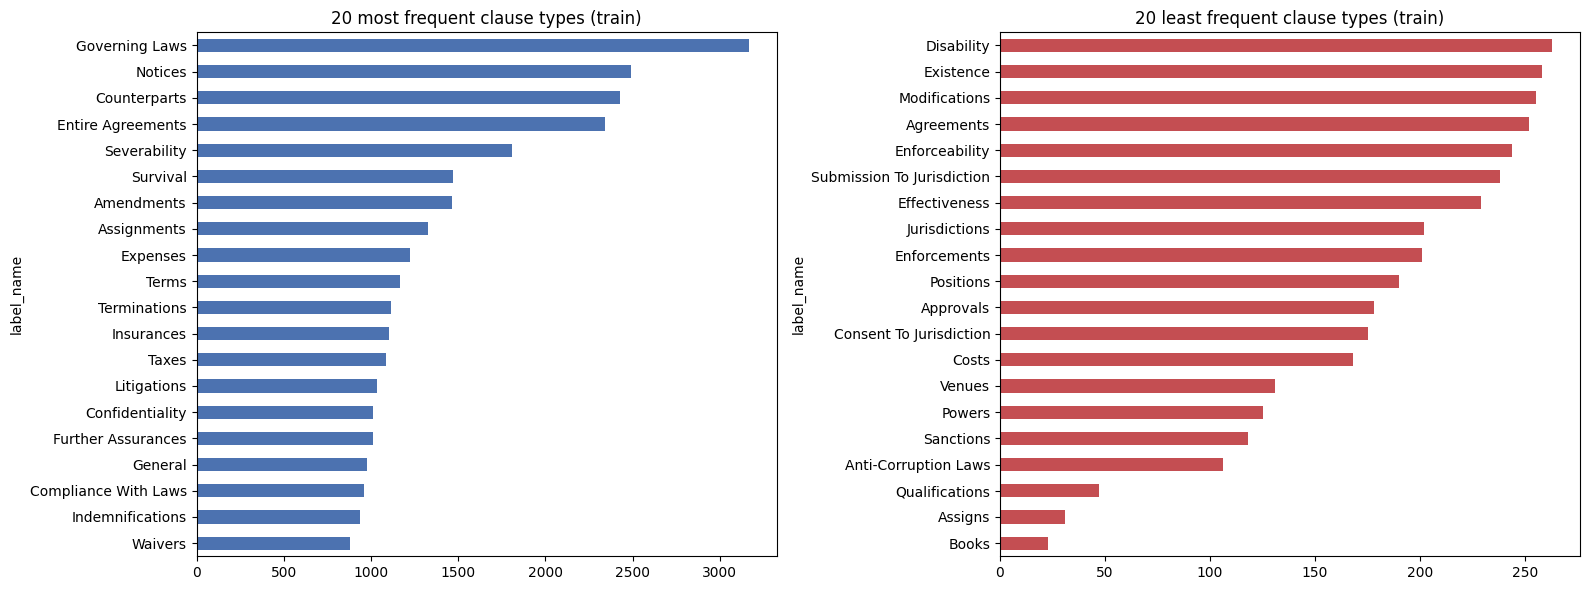

In [ ]:
import matplotlib.pyplot as plt
counts = df_train["label_name"].value_counts()
print(f"Classes: {len(counts)} | largest: {counts.iloc[0]} ({counts.index[0]}) | smallest: {counts.iloc[-1]} ({counts.index[-1]})")
print(f"Imbalance ratio (largest / smallest): {counts.iloc[0] / counts.iloc[-1]:.1f}")
print(f"Share of data in the top 10 classes: {counts.head(10).sum() / counts.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
counts.head(20).sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("20 most frequent clause types (train)")
counts.tail(20).sort_values().plot.barh(ax=axes[1], color="#C44E52")
axes[1].set_title("20 least frequent clause types (train)")
plt.tight_layout(); plt.show()

Text length

       n_words  n_chars
count  60000.0  60000.0
mean     113.9    707.7
std       96.3    600.1
min        3.0     22.0
25%       48.0    299.0
50%       86.0    532.0
75%      148.0    919.0
max     1215.0   7803.0


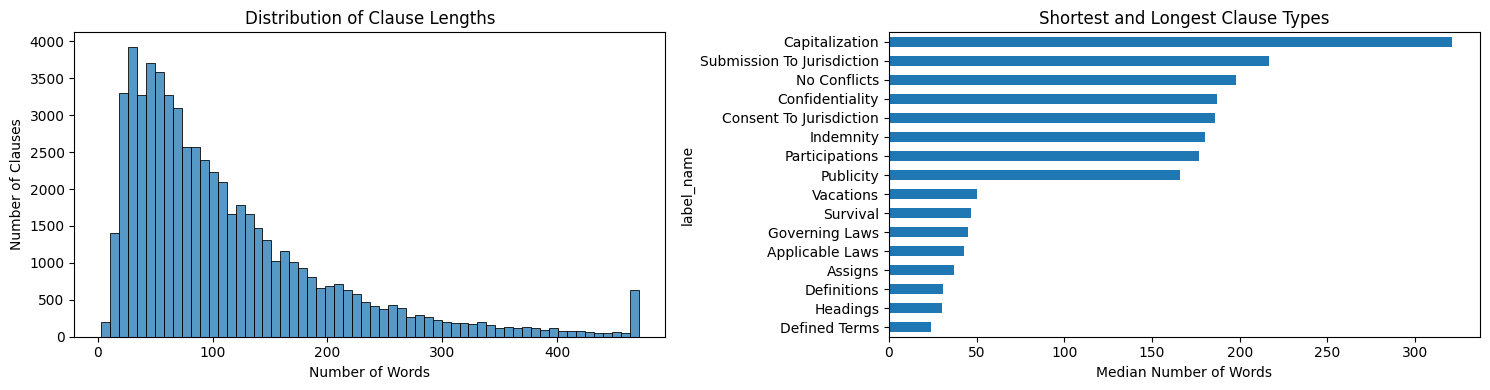

In [ ]:
import seaborn as sns
# Calculate the number of words and characters in each clause
for d in splits.values():
    d["n_words"] = d["text"].str.split().str.len()
    d["n_chars"] = d["text"].str.len()

# Display basic statistics
print(df_train[["n_words", "n_chars"]].describe().round(1))

# Plot clause lengths
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
max_words = df_train["n_words"].quantile(0.99) # limit the chart to the 99th percentile

# Distribution of clause lengths
sns.histplot(df_train["n_words"].clip(upper=max_words), bins=60, ax=axes[0])
axes[0].set_title("Distribution of Clause Lengths")
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Number of Clauses")

# Compare the shortest and longest clause types
med = df_train.groupby("label_name")["n_words"].median().sort_values()

pd.concat([med.head(8), med.tail(8)]).plot.barh(ax=axes[1])
axes[1].set_title("Shortest and Longest Clause Types")
axes[1].set_xlabel("Median Number of Words")

plt.tight_layout()
plt.show()

Vocabulary.

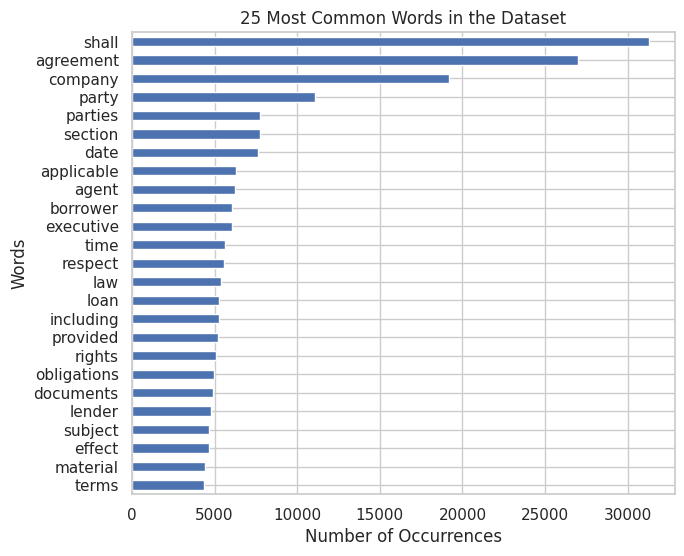

In [ ]:
# Select a sample of up to 20,000 clauses
sample = df_train.sample(min(20_000, len(df_train)), random_state=SEED)

# Count the most common words, excluding common words like "the", "is" and "and"
cv = CountVectorizer(stop_words="english", max_features=25)
word_counts = cv.fit_transform(sample["text"]).sum(axis=0)

# Display the 25 most common words
top_words = pd.Series(
    np.asarray(word_counts).ravel(),
    index=cv.get_feature_names_out()
).sort_values()

top_words.plot.barh(figsize=(7, 6))
plt.title("25 Most Common Words in the Dataset")
plt.xlabel("Number of Occurrences")
plt.ylabel("Words")
plt.show()

In [ ]:
# Find words that are common in each of the 6 largest clause types
tv = TfidfVectorizer(stop_words="english", min_df=5, max_features=20_000)
Xs = tv.fit_transform(sample["text"])
terms = tv.get_feature_names_out()
overall = np.asarray(Xs.mean(axis=0)).ravel()

rows = []
for name in counts.index[:6]:
    mask = (sample["label_name"] == name).values
    # Find words with higher scores in this clause type
    scores = np.asarray(Xs[mask].mean(axis=0)).ravel() - overall
    words = terms[np.argsort(scores)[-8:][::-1]]
    rows.append((name, ", ".join(words)))
pd.DataFrame(rows, columns=["Clause Type", "Common Words"])

,Clause Type,Common Words
0,Governing Laws,"laws, state, governed, construed, accordance, york, new, law"
1,Notices,"address, given, notice, notices, mail, sent, writing, delivered"
2,Counterparts,"counterparts, executed, original, constitute, counterpart, deemed, facsimile, instrument"
3,Entire Agreements,"matter, agreement, agreements, entire, parties, subject, oral, understandings"
4,Severability,"provision, unenforceable, invalid, illegal, provisions, jurisdiction, held, remaining"
5,Survival,"survive, termination, obligations, expiration, warranties, section, representations, sections"


EDA Observations



1. The clause types are unevenly distributed. Governing Laws is the most common, with 3,167 clauses, while Books has only 23. The 10 most common clause types account for about 31% of the dataset. This means the model needs to account for both common and less common clause types.

2. Clause lengths vary considerably. Most clauses are relatively short, with a median of 86 words, but the longest 1% contain more than 471 words. The longest clause has 1,215 words.

3. There are 920 repeated texts and 3 texts associated with more than one label in the training data. These will be removed in the next section to avoid using duplicate or unclear examples when training the model.

4. Some clauses in the validation and test sets also appear in the training set. These overlapping clauses will be removed from the training set to prevent data leakage and ensure a more reliable evaluation of the model's performance.

5. Different clause types have words and phrases that help distinguish them. For example, words such as 'counterparts', 'notice' and 'severability' are useful indicators of certain clause types. However, some types may use similar language which may make them harder for the model to distinguish.

In [ ]:
def norm_key(s):
    if pd.isna(s):
        return ""
    return re.sub(r"\s+", " ", str(s)).strip().lower()

df_train = df_train.copy()
df_validation = df_validation.copy()
df_test = df_test.copy()

df_train["key"] = df_train["text"].map(norm_key)
df_validation["key"] = df_validation["text"].map(norm_key)
df_test["key"] = df_test["text"].map(norm_key)

Data Cleaning.


1. Replace URLs with **url** and standalone numbers with **num**. This helps the model focus on the wording of clauses rather than specific website addresses, dates or numerical values.

Unnecessary spaces and line breaks are also removed. Legal identifiers such as 144A preserved.

In [ ]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
NUM_RE = re.compile(r"(?<![\w-])\d+(?:[,./]\d+)*(?![\w-])")

def clean_text(s):
    if pd.isna(s):
        return ""

    s = str(s)
    s = URL_RE.sub(" url ", s)
    s = NUM_RE.sub(" num ", s)
    return re.sub(r"\s+", " ", s).strip()

2.Remove Blank Texts-
Empty clauses do not provide useful information for training so we decided to remove rows with missing or blank text from the training dataset.
The original validation and test datasets are left unchanged.

In [ ]:
log = [("Raw training data", len(df_train))]

train = df_train.copy()
val = df_validation.copy()
test = df_test.copy()

train = train[train["key"] != ""].copy()

log.append(("After removing blank texts", len(train)))

Remove conflicting labels - text assigned to more than one label

In [ ]:
labels_per_text = train.groupby("key")["label"].nunique()

conflicting = labels_per_text[labels_per_text > 1].index

train = train[~train["key"].isin(conflicting)].copy()

log.append(("After removing conflicting-label texts", len(train)))

Remove Duplicate Texts-
Keep only one occurrence of each text in the training dataset.

In [ ]:
train = train.drop_duplicates(subset="key", keep="first").copy()

log.append(("After removing duplicate texts", len(train)))

Remove Overlap with Validation and Test Data -
Remove training texts that also appear in validation or test. This prevents data leakage while keeping both evaluation datasets unchanged.

In [ ]:
evaluation_keys = set(val["key"]) | set(test["key"])

train = train[~train["key"].isin(evaluation_keys)].copy()

log.append(("After removing validation/test overlap", len(train)))

Clean the text in all three Datasets i.e
apply the same cleaning function to all three datasets.

In [ ]:
train["text"] = train["text"].map(clean_text)
val["text"] = val["text"].map(clean_text)
test["text"] = test["text"].map(clean_text)

train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

**Prepare the Modelling Data**

In preparation for modelling we separate the text and labels for training, validation and testing.

In [ ]:
X_train, y_train = train["text"], train["label"].values
X_val, y_val = val["text"], val["label"].values
X_test, y_test = test["text"], test["label"].values

Check the Final Datasets

Display the number of training rows remaining after each cleaning step, the final dataset sizes and the number of classes.

In [ ]:
display(pd.DataFrame(log, columns=["Cleaning Step", "Training Rows"]))

print(
    "Final modelling sets ->",
    "train:", len(train),
    "| validation:", len(val),
    "| test:", len(test)
)

print("Classes in final train set:", train["label"].nunique(), "of", classes)

,Cleaning Step,Training Rows
0,Raw training data,60000
1,After removing blank texts,60000
2,After removing conflicting-label texts,59994
3,After removing duplicate texts,59077
4,After removing validation/test overlap,58560


Final modelling sets -> train: 58560 | validation: 10000 | test: 10000
Classes in final train set: 100 of 100


**5. Model training and Validation**


**Approach.** Each clause already has an assigned category, making this a supervised learning task. Since the goal is to predict one of several clause types, this is a multi-class classification problem. Regression is not suitable because the target is a category rather than a numerical value.

**Main model.** We use Logistic Regression as our main model. It works well with text classification when combined with TF-IDF, is relatively fast to train and provides a good starting point for comparing different algorithms. TF-IDF converts the clauses into numerical features that the model can use to learn patterns associated with each clause type.

**Regularisation.** We use regularisation to help prevent the model from becoming too closely fitted to the training data. Logistic Regression uses a parameter called `C` to control its strength. A smaller value applies stronger regularisation, while a larger value applies weaker regularisation. We test values of 1, 10 and 100.

**Validation.** We use 3-fold stratified cross-validation with GridSearchCV. The training data is divided into three parts, with each part taking a turn as the validation fold while the model trains on the other two. Each fold maintains roughly the same distribution of clause types. We use macro-F1 to compare the results because it gives equal importance to all clause types, including those with fewer examples. The best-performing `C` value is selected.

**Final evaluation.** After selecting the best settings, we evaluate the model using the separate validation dataset and examine its predictions and mistakes. The test dataset remains untouched until the final model comparison in Section 6.

**Set Up the Model Pipeline**

We use TF-IDF to convert the legal clauses into numerical values that the model can understand. These values are then passed to Logistic Regression, which learns to predict the clause types.

Both steps are placed in one pipeline. This ensures that TF-IDF learns from the training data only, including during cross-validation, helping prevent data leakage.

In [ ]:
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words=None,
        max_features=MAX_FEATURES
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=SEED
    ))
])

In [ ]:
# Set the parameters to test
param_grid = {
    "clf__C": LR_C_GRID
}

**Perform Cross-Validation**

We use GridSearchCV to test each C value using stratified cross-validation.

Stratified folds help maintain a similar distribution of clause types in each fold. The models are compared using macro-F1, which gives equal importance to each clause type, including those with fewer examples.

The best-performing parameter is selected automatically.

In [ ]:
cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

grid = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

grid.fit(X_train, y_train)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(max_features=30000)),
                                       ('clf',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=42))]),
             n_jobs=-1, param_grid={'clf__C': [1, 10, 100]},
             return_train_score=True, scoring='f1_macro', verbose=1)

**Identify the Best Model**

Display the best C value and its cross-validation score. We also compare training and cross-validation scores to check whether the model may be overfitting.

In [ ]:
print("Best C:", grid.best_params_["clf__C"])
print("Best CV Macro-F1:", round(grid.best_score_, 4))

results = pd.DataFrame(grid.cv_results_)

display(results[[
    "param_clf__C",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]])

Best C: 10
Best CV Macro-F1: 0.7777


,param_clf__C,mean_train_score,mean_test_score,std_test_score
0,1,0.790923,0.724091,0.002080
1,10,0.952132,0.777677,0.002941
2,100,0.992360,0.776143,0.001904


The results show that C=10 achieved the highest cross-validation Macro-F1 score of approximately 0.7777

**Evaluate on the Validation Set**

We then use the selected model to make predictions on the validation dataset. Compare its predictions with the actual labels to see how well it performs on data that was not used during training or parameter selection.

In [ ]:
best_lr = grid.best_estimator_

y_val_pred = best_lr.predict(X_val)

print("Validation Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Validation Macro-F1:", round(f1_score(y_val, y_val_pred, average="macro"), 4))

print(classification_report(
    y_val,
    y_val_pred,
    zero_division=0
))

Validation Accuracy: 0.8518
Validation Macro-F1: 0.7741
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        48
           1       0.38      0.50      0.43        22
           2       0.86      0.90      0.88       257
           3       0.95      0.69      0.80        26
           4       0.58      0.10      0.17        69
           5       0.71      0.58      0.64        26
           6       0.94      0.99      0.96        68
           7       0.82      0.92      0.87       208
           8       0.00      0.00      0.00         3
           9       0.64      0.70      0.67        69
          10       0.76      0.72      0.74       106
          11       0.99      0.99      0.99       114
          12       0.80      0.77      0.78        82
          13       0.66      0.74      0.70        93
          14       0.00      0.00      0.00         0
          15       0.94      0.97      0.96        68
          16       0.99  

The selected Logistic Regression model achieved 85.18% accuracy and a Macro-F1 score of 77.41% on the validation set. These relatively close cross-validation and validation scores suggest that its performance is consistent across the two evaluation approaches.

**Examine Classification Errors**

Next we use a confusion matrix  to help identify which clause types the model predicts correctly and which ones it confuses with others.

In [ ]:
cm = confusion_matrix(y_val, y_val_pred, labels=range(classes))
np.fill_diagonal(cm, 0)

idx = np.dstack(
    np.unravel_index(
        np.argsort(cm.ravel())[::-1][:10],
        cm.shape
    )
)[0]

pd.DataFrame([
    {
        "true clause type": label_names[i],
        "predicted as": label_names[j],
        "count": int(cm[i, j])
    }
    for i, j in idx
])

,true clause type,predicted as,count
0,Applicable Laws,Governing Laws,58
1,Defined Terms,Definitions,21
2,Integration,Entire Agreements,20
3,Withholdings,Tax Withholdings,19
4,No Waivers,Waivers,18
5,Definitions,Defined Terms,18
6,Authorizations,Authority,16
7,Tax Withholdings,Withholdings,16
8,Taxes,Withholdings,13
9,Warranties,Representations,13


**5.Comparing the main model with other models**

After building and evaluating Logistic Regression as our main model, we now compare it with other classification algorithms to see whether they can achieve better results. We use Linear Support Vector Machine (LinearSVC), Complement Naive Bayes and Random Forest for this comparison. These models use different approaches to classify text and may perform differently across the 100 clause types.

We use the same cleaned data, TF-IDF process, cross-validation method and scoring measures for all three models to makes the comparison fair.

In [ ]:
# Define the cross-validation strategy
cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

# Define the Linear SVC pipeline
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words=None,
        max_features=MAX_FEATURES
    )),
    ("clf", LinearSVC(random_state=SEED))
])

# Define the hyperparameters to test
svm_params = {
    "clf__C": [0.1, 1, 10]
}

# Set up GridSearchCV
svm_gs = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Train and tune Linear SVC
svm_gs.fit(X_train, y_train)

# Define the Complement Naive Bayes pipeline
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words=None,
        max_features=MAX_FEATURES
    )),
    ("clf", ComplementNB())
])

# Define the hyperparameters to test
nb_params = {
    "clf__alpha": [0.01, 0.1, 1.0]
}

# Set up GridSearchCV
nb_gs = GridSearchCV(
    nb_pipeline,
    nb_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Train and tune Complement Naive Bayes
nb_gs.fit(X_train, y_train)

#cross-validation results
# Display Linear SVC results
print("Linear SVC CV results:")
display(pd.DataFrame(svm_gs.cv_results_)[
    ["param_clf__C", "mean_train_score", "mean_test_score", "std_test_score"]
])

# Display Complement Naive Bayes results
print("Complement Naive Bayes CV results:")
display(pd.DataFrame(nb_gs.cv_results_)[
    ["param_clf__alpha", "mean_train_score", "mean_test_score", "std_test_score"]
])

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Linear SVC CV results:


,param_clf__C,mean_train_score,mean_test_score,std_test_score
0,0.1,0.805146,0.725562,0.000802
1,1.0,0.942271,0.775595,0.001481
2,10.0,0.989641,0.768527,0.001357


Complement Naive Bayes CV results:


,param_clf__alpha,mean_train_score,mean_test_score,std_test_score
0,0.01,0.686644,0.561570,0.002717
1,0.10,0.674027,0.568430,0.002641
2,1.00,0.638844,0.570653,0.003265


In [ ]:
# Define the Random Forest pipeline
rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words=None,
        max_features=MAX_FEATURES
    )),
    ("clf", RandomForestClassifier(
        n_estimators=200,
        random_state=SEED,
        n_jobs=-1
    ))
])

# Define the hyperparameters to test
rf_params = {
    "clf__max_depth": [None, 20, 40]
}

# Set up GridSearchCV
rf_gs = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Train and tune Random Forest
rf_gs.fit(X_train, y_train)

# Display cross-validation results
print("Random Forest CV results:")
display(pd.DataFrame(rf_gs.cv_results_)[
    ["param_clf__max_depth", "mean_train_score", "mean_test_score", "std_test_score"]
    ])

Fitting 3 folds for each of 3 candidates, totalling 9 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest CV results:


,param_clf__max_depth,mean_train_score,mean_test_score,std_test_score
0,None,0.999743,0.776378,0.002517
1,20,0.792491,0.595255,0.006917
2,40,0.978753,0.733691,0.003407


In [ ]:
# Generate predictions on the validation set
y_lr_pred = best_lr.predict(X_val)
y_svm_pred = svm_gs.best_estimator_.predict(X_val)
y_nb_pred = nb_gs.best_estimator_.predict(X_val)
y_rf_pred = rf_gs.best_estimator_.predict(X_val)

In [ ]:
# Collect validation results
models = {
    "Logistic Regression": y_lr_pred,
    "Linear SVC": y_svm_pred,
    "Complement Naive Bayes": y_nb_pred,
    "Random Forest": y_rf_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(y_val, predictions, average="macro")
    })

# Display results
results_df = pd.DataFrame(results)
display(results_df.sort_values("Macro-F1", ascending=False))

,Model,Accuracy,Macro-F1
3,Random Forest,0.8595,0.789943
0,Logistic Regression,0.8518,0.774127
1,Linear SVC,0.8535,0.773247
2,Complement Naive Bayes,0.7322,0.575710


**Model comparison**


**Linear SVC**

Linear SVC achieved its best cross-validation Macro-F1 score of approximately 0.7756 with C=1. Its performance was very close to Logistic Regression, suggesting that both linear models are effective approaches for this text classification task.

**Complement Naive Bayes**

Complement Naive Bayes achieved a cross-validation Macro-F1 score of approximately 0.5707, considerably below the other models. Its validation Macro-F1 was approximately 0.5757. This indicates that it was less effective at distinguishing the 100 clause categories in this dataset.

**Random Forest**

Random Forest achieved its best cross-validation Macro-F1 score of approximately 0.7764. However, its training Macro-F1 was approximately 0.9997, indicating a substantial gap between training and cross-validation performance. This suggests that the model fits the training data very closely without achieving a corresponding improvement in cross-validation performance.

In [ ]:
for name, predictions in models.items():
    print(f"\n{name} Classification Report:")
    print(classification_report(
        y_val,
        predictions,
        labels=range(classes),
        target_names=label_names,
        zero_division=0
    ))


Logistic Regression Classification Report:
                              precision    recall  f1-score   support

                 Adjustments       0.91      0.85      0.88        48
                  Agreements       0.38      0.50      0.43        22
                  Amendments       0.86      0.90      0.88       257
        Anti-Corruption Laws       0.95      0.69      0.80        26
             Applicable Laws       0.58      0.10      0.17        69
                   Approvals       0.71      0.58      0.64        26
                 Arbitration       0.94      0.99      0.96        68
                 Assignments       0.82      0.92      0.87       208
                     Assigns       0.00      0.00      0.00         3
                   Authority       0.64      0.70      0.67        69
              Authorizations       0.76      0.72      0.74       106
                 Base Salary       0.99      0.99      0.99       114
                    Benefits       0.80      

In [ ]:
# Generate the confusion matrix
cm_rf = confusion_matrix(
    y_val,
    y_rf_pred,
    labels=range(classes)
)

# Remove correct predictions
np.fill_diagonal(cm_rf, 0)

# Find the 10 most common misclassifications
idx = np.dstack(
    np.unravel_index(
        np.argsort(cm_rf.ravel())[::-1][:10],
        cm_rf.shape
    )
)[0]

# Create a table of misclassifications
mistakes_rf = [
    {
        "true clause type": label_names[i],
        "predicted as": label_names[j],
        "count": int(cm_rf[i, j])
    }
    for i, j in idx
    if cm_rf[i, j] > 0
]

display(pd.DataFrame(mistakes_rf))

,true clause type,predicted as,count
0,Applicable Laws,Governing Laws,58
1,Integration,Entire Agreements,25
2,Defined Terms,Definitions,24
3,Indemnity,Indemnifications,22
4,No Waivers,Waivers,19
5,Tax Withholdings,Withholdings,19
6,Modifications,Amendments,18
7,Successors,Binding Effects,17
8,Authorizations,Authority,15
9,Warranties,Representations,14


In [ ]:
# Generate predictions using the selected Logistic Regression model
y_test_pred = best_lr.predict(X_test)

# Calculate final performance
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Test Macro-F1:", f1_score(y_test, y_test_pred, average="macro"))

# Display classification report
print(classification_report(
    y_test,
    y_test_pred,
    labels=range(classes),
    target_names=label_names,
    zero_division=0
))

Test Accuracy: 0.8529
Test Macro-F1: 0.7893366561814537
                              precision    recall  f1-score   support

                 Adjustments       0.91      0.90      0.90        88
                  Agreements       0.66      0.40      0.49        48
                  Amendments       0.78      0.88      0.83       224
        Anti-Corruption Laws       0.96      1.00      0.98        23
             Applicable Laws       0.42      0.09      0.15        53
                   Approvals       0.65      0.58      0.61        26
                 Arbitration       0.80      0.94      0.86        47
                 Assignments       0.82      0.87      0.84       195
                     Assigns       0.00      0.00      0.00         4
                   Authority       0.64      0.60      0.62        62
              Authorizations       0.81      0.74      0.77        90
                 Base Salary       0.98      0.96      0.97       112
                    Benefits     

The classification report shows that performance varies across clause types. The model performs particularly well on several categories but struggles with others, including Applicable Laws, Assigns and Powers

In [ ]:

# Store the model performance results
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVC",
        "Complement Naive Bayes",
        "Random Forest"
    ],

    "CV Macro-F1": [
        0.777677,
        0.775595,
        0.570653,
        0.776378
    ],

    "Validation Macro-F1": [
        0.774127,
        0.773247,
        0.575710,
        0.789943
    ],

    "Test Macro-F1": [
        0.789337,
        np.nan,
        np.nan,
        0.792300
    ]
})

# Display the comparison table
display(results.round(4))

,Model,CV Macro-F1,Validation Macro-F1,Test Macro-F1
0,Logistic Regression,0.7777,0.7741,0.7893
1,Linear SVC,0.7756,0.7732,NaN
2,Complement Naive Bayes,0.5707,0.5757,NaN
3,Random Forest,0.7764,0.7899,0.7923


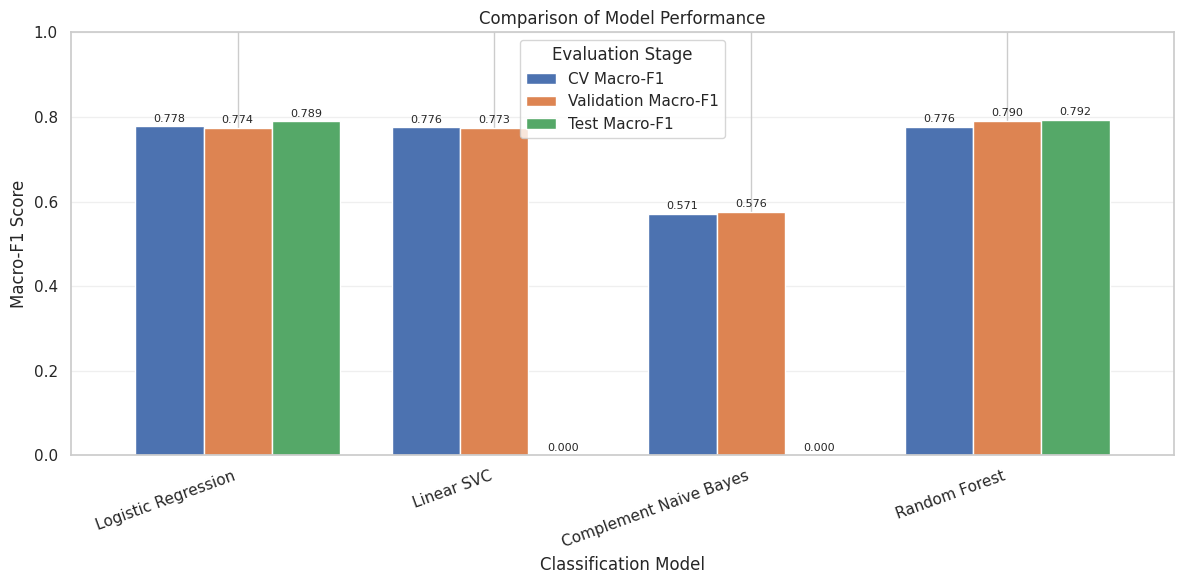

In [ ]:
# Set the model names as the index
plot_data = results.set_index("Model")

# Create the grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Add chart details
plt.title("Comparison of Model Performance")
plt.xlabel("Classification Model")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Stage")
plt.grid(axis="y", alpha=0.3)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=8)

plt.tight_layout()
plt.show()

**Limitations**

The results are affected by class imbalance and similarities between certain clause categories.

Some categories have very few examples, making it difficult for the models to learn their distinguishing characteristics.

Additionally, the dataset primarily represents US legal agreements, so the models may not perform equally well on legal documents from other jurisdictions, such as Kenya.

**REFERENCES**

Chalkidis et al. (2021), LexGLUE: A Benchmark Dataset for Legal Language Understanding in English, which is arXiv 2110.00976.

Tuggener et al. (2020), LEDGAR: A Large-Scale Multi-label Corpus for Text Classification of Legal Provisions in Contracts, LREC 2020.